# PPO on LunarLander-v3

A Proximal Policy Optimization (PPO) agent learns to land the lunar module on its own, by trial and error.
The environment is considered solved when the agent reaches a mean score of at least 200 over 100 consecutive episodes, played without exploration.

The notebook reads from top to bottom and must run with *Restart & Run All*.

1. Setup
2. Environment
3. Random baseline
4. Actor and critic
5. Rollout storage and advantages
6. PPO update
7. Training
8. Results
9. Experiments
10. Comparison with DQN
11. Conclusion

## 1. Setup

In [132]:
import copy
import random
import time
from collections import Counter
from collections.abc import Callable
from dataclasses import asdict, dataclass, replace
from pathlib import Path
from typing import Protocol

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display
from torch import nn
from torch.distributions import Categorical


### Reproducibility

`set_seed` fixes the three random generators of Python, NumPy and PyTorch (initial weights, sampled actions, shuffled minibatches), so that every run gives the same results. It is a function because each training of section 8 starts from its own seed. The environment has its own generator, seeded with `env.reset(seed=...)`.

In [133]:
def set_seed(*, seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


SEED = 42
set_seed(seed=SEED)

## 2. Environment

LunarLander-v3 is a 2D landing task simulated with Box2D. The training environment has no `render_mode`: the agent only reads the observation vector, and drawing frames would slow training down.

| Index | Observation | | Action | Effect |
|---|---|---|---|---|
| 0, 1 | position `x`, `y` (pad at $x = 0$, screen edges at $x = \pm 1$) | | 0 | do nothing |
| 2, 3 | velocity `v_x`, `v_y` | | 1 | fire the left orientation engine |
| 4, 5 | angle `theta` and angular velocity | | 2 | fire the main engine |
| 6, 7 | left and right leg contact (1 or 0) | | 3 | fire the right orientation engine |

An episode ends with `terminated` (crash, out of the viewport, or at rest: there is no future reward) or `truncated` (limit of 1000 steps: the lander could have kept going). The two flags are kept apart everywhere, since section 5 treats them differently.

`env.reset(seed=SEED)` seeds the environment once; the following resets continue the same sequence, so the episodes are reproducible and all different. The dimensions are read from the observation and action spaces.

In [134]:
ENV_ID = "LunarLander-v3"

env = gym.make(ENV_ID)
env.action_space.seed(seed=SEED)
state, _ = env.reset(seed=SEED)
state_dim = env.observation_space.shape[0]
n_actions = env.action_space.n

print("State dimension:", state_dim)
print("Number of actions:", n_actions)

State dimension: 8
Number of actions: 4


## 3. Random baseline

An agent that picks its actions at random gives a reference score, and checks the evaluation tools that are reused as they are for the trained agent.

### Episode result and end reason

`EpisodeResult` is a frozen dataclass holding the total reward, the number of steps and the end reason of one episode. The subject requires these three values for every episode.

| Reason | Condition | Flag |
|---|---|---|
| `crash` | the body touched the ground (`env.unwrapped.game_over`) | `terminated` |
| `out_of_viewport` | `abs(x) >= 1` on the final observation, the condition Gymnasium uses ($x$ is normalized so that the screen edges are at $\pm 1$) | `terminated` |
| `at_rest` | the only cause left: the lander stopped moving | `terminated` |
| `truncated` | the limit of 1000 steps | `truncated` |

The crash is tested first: a crash can also throw the lander out of the screen, and its real cause is the crash. The reasons are constants, so a typo cannot create a fifth one.

In [135]:
CRASH = "crash"
OUT_OF_VIEWPORT = "out_of_viewport"
AT_REST = "at_rest"
TRUNCATED = "truncated"
END_REASONS = (CRASH, OUT_OF_VIEWPORT, AT_REST, TRUNCATED)

VIEWPORT_X_LIMIT = 1.0


@dataclass(frozen=True)
class EpisodeResult:
    total_reward: float
    n_steps: int
    end_reason: str


def get_end_reason(*, env: gym.Env, final_state: np.ndarray, terminated: bool) -> str:
    if not terminated:
        return TRUNCATED
    if env.unwrapped.game_over:
        return CRASH
    x_position = final_state[0]
    if abs(x_position) >= VIEWPORT_X_LIMIT:
        return OUT_OF_VIEWPORT
    return AT_REST

### Random agent

An **agent** receives the observation by name and returns an action. The contract is the `Protocol` `Agent`: any function with the signature `(*, state: np.ndarray) -> int` matches it, so the random agent, the trained PPO agent and the agent of `model.py` all work with the same evaluation code. The random agent draws its action with `env.action_space.sample()`, seeded in section 2.

In [136]:
class Agent(Protocol):
    def __call__(self, *, state: np.ndarray) -> int: ...


def random_agent(*, state: np.ndarray) -> int:
    return int(env.action_space.sample())

### Playing one episode

`run_episode` resets the environment, lets the agent act until `terminated` or `truncated`, and returns the `EpisodeResult`. The end reason is read from `next_state`, the observation returned by the last `env.step`, since Gymnasium tests the end conditions on it.

In [137]:
def run_episode(*, env: gym.Env, agent: Agent) -> EpisodeResult:
    state, _ = env.reset()
    total_reward = 0.0
    n_steps = 0

    while True:
        action = agent(state=state)
        next_state, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward
        n_steps += 1

        if terminated or truncated:
            return EpisodeResult(
                total_reward=float(total_reward),
                n_steps=n_steps,
                end_reason=get_end_reason(env=env, final_state=next_state, terminated=terminated),
            )

        state = next_state


print(run_episode(env=env, agent=random_agent))

EpisodeResult(total_reward=-108.55402945184308, n_steps=106, end_reason='crash')


### Evaluation over 100 episodes

The subject measures an agent over 100 consecutive episodes without exploration: it is solved when the mean reward reaches 200. The baseline uses the same protocol. Three functions split the work: `evaluate` plays the episodes, `summarize_results` computes the mean, the standard deviation, the mean length and the count of each end reason (0 included, so that the tables of every agent compare line by line), and `plot_reward_distribution` draws the histogram with the mean and the threshold of 200.

In [138]:
SOLVED_THRESHOLD = 200.0


def evaluate(*, env: gym.Env, agent: Agent, n_episodes: int) -> list[EpisodeResult]:
    return [run_episode(env=env, agent=agent) for _ in range(n_episodes)]


@dataclass(frozen=True)
class EvaluationSummary:
    mean_reward: float
    std_reward: float
    mean_steps: float
    end_reasons: dict[str, int]


def summarize_results(*, results: list[EpisodeResult]) -> EvaluationSummary:
    rewards = [result.total_reward for result in results]
    steps = [result.n_steps for result in results]
    end_reason_counts = Counter(result.end_reason for result in results)
    return EvaluationSummary(
        mean_reward=float(np.mean(rewards)),
        std_reward=float(np.std(rewards)),
        mean_steps=float(np.mean(steps)),
        end_reasons={reason: end_reason_counts[reason] for reason in END_REASONS},
    )


def plot_reward_distribution(*, results: list[EpisodeResult], title: str) -> None:
    rewards = [result.total_reward for result in results]
    plt.hist(rewards, bins=20)
    plt.axvline(np.mean(rewards), color="red", linestyle="--", label="mean")
    plt.axvline(SOLVED_THRESHOLD, color="green", linestyle=":", label=f"solved ({SOLVED_THRESHOLD:.0f})")
    plt.xlabel("Total reward per episode")
    plt.ylabel("Number of episodes")
    plt.title(title)
    plt.legend()
    plt.show()

Random agent over 100 episodes
Mean reward: -177.2 ± 94.6
Mean steps:  93.9
End reasons: {'crash': 95, 'out_of_viewport': 5, 'at_rest': 0, 'truncated': 0}


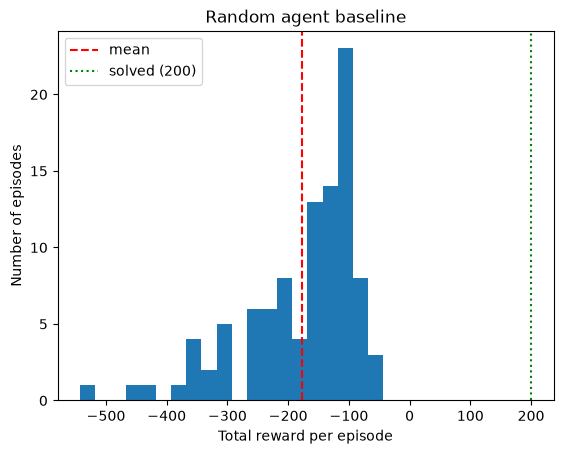

In [139]:
N_EVAL_EPISODES = 100

baseline_results = evaluate(env=env, agent=random_agent, n_episodes=N_EVAL_EPISODES)
baseline_summary = summarize_results(results=baseline_results)

print(f"Random agent over {N_EVAL_EPISODES} episodes")
print(f"Mean reward: {baseline_summary.mean_reward:.1f} ± {baseline_summary.std_reward:.1f}")
print(f"Mean steps:  {baseline_summary.mean_steps:.1f}")
print(f"End reasons: {baseline_summary.end_reasons}")

plot_reward_distribution(results=baseline_results, title="Random agent baseline")

### Baseline results

| Measure | Random agent |
|---|---|
| mean reward | −177.2 ± 94.6 |
| median, best, worst | −143.8, −43.4, −542.5 |
| mean episode length | 93.9 steps (about 2 seconds) |
| end reasons | 95 crashes, 5 out of viewport, 0 at rest, 0 truncated |

No episode is positive: the mean is about 377 points below the threshold of 200. Without control, the lander falls and crashes in about 2 seconds. The distribution has a long tail down to −542.5 (random firings that push the lander away or faster into the ground), which pulls the mean below the median. The DQN notebook measured a close baseline (−173.4 ± 110.0).

## 4. Actor and critic

| Network | Input | Output |
|---|---|---|
| **actor** | the observation | one probability per action: the **policy** |
| **critic** | the observation | $V(s)$: the total reward expected from this state with the current policy |

During training, the action is **sampled** from the probabilities of the actor: this is how PPO explores, without epsilon-greedy. During evaluation, the agent takes the most probable action. The critic never chooses: it tells whether an action did better or worse than expected (section 5).

The actor and the critic are **two separate networks** rather than one network with two heads: the two losses do not compete on shared weights, so no coefficient has to balance them; it is the default of Stable-Baselines3 and CleanRL for vector observations; and a shared body only saves computation for large inputs such as images.

### Configuration

All the hyperparameters live in one frozen dataclass, `PPOConfig`: a typo in a field name is an immediate error, `PPOConfig()` is the reference configuration, and an experiment creates a modified copy with `replace(config, ...)` (section 9). Each section adds and justifies its own fields.

| Field | Value | Reason |
|---|---|---|
| `hidden_size` | 64 | neurons in each of the two hidden layers. The standard size for PPO on small vector observations (Stable-Baselines3, CleanRL). The DQN notebook uses 128. |

In [140]:
@dataclass(frozen=True)
class PPOConfig:
    hidden_size: int = 64
    n_steps: int = 2048
    gamma: float = 0.99
    gae_lambda: float = 0.95
    learning_rate: float = 3e-4
    n_epochs: int = 10
    batch_size: int = 64
    clip_range: float = 0.2
    entropy_coef: float = 0.01
    max_grad_norm: float = 0.5
    total_timesteps: int = 1_000_000
    eval_interval: int = 10
    n_eval_episodes: int = 10


config = PPOConfig()
print("Config:", config)


Config: PPOConfig(hidden_size=64, n_steps=2048, gamma=0.99, gae_lambda=0.95, learning_rate=0.0003, n_epochs=10, batch_size=64, clip_range=0.2, entropy_coef=0.01, max_grad_norm=0.5, total_timesteps=1000000, eval_interval=10, n_eval_episodes=10)


### Building the networks

```
                 ┌─ Linear(8, 64) ─ Tanh ─ Linear(64, 64) ─ Tanh ─ Linear(64, 4) ─► 4 logits   actor
observation (8) ─┤
                 └─ Linear(8, 64) ─ Tanh ─ Linear(64, 64) ─ Tanh ─ Linear(64, 1) ─► V(s)       critic
```

`build_mlp` builds both networks as an `nn.Sequential` with two hidden layers.

* **Tanh rather than ReLU**: bounded activations and smoother policy updates. It is the default of Stable-Baselines3 and CleanRL for PPO, and Andrychowicz et al. (2021, *What Matters in On-Policy Reinforcement Learning?*) found it better than ReLU for PPO.
* **Logits as outputs**: the actor has no softmax; `Categorical(logits=...)` computes the probabilities and their logarithms in a numerically stable way.
* **Orthogonal initialization**, as in the reference implementations (*The 37 Implementation Details of Proximal Policy Optimization*, Huang et al., 2022):

| Layers | Gain | Reason |
|---|---|---|
| hidden layers | $\sqrt{2}$ | keeps the scale of the signal from one layer to the next |
| actor output | 0.01 | initial logits close to 0, so an almost uniform initial policy: the agent starts with no preference and explores. Andrychowicz et al. (2021) found this small last layer to be one of the choices that matter most for PPO |
| critic output | 1 | initial values on a normal scale |
| biases | 0 | no initial offset |

With the default initialization of PyTorch, the initial policy already prefers some actions only because of the random draw. The gains are constants rather than fields of `PPOConfig`, since this notebook does not tune them.

In [141]:
HIDDEN_GAIN = np.sqrt(2)
ACTOR_OUTPUT_GAIN = 0.01
CRITIC_OUTPUT_GAIN = 1.0


def initialize_layer(*, layer: nn.Linear, gain: float) -> None:
    nn.init.orthogonal_(layer.weight, gain=gain)
    nn.init.zeros_(layer.bias)


def build_mlp(*, input_size: int, hidden_size: int, output_size: int, output_gain: float) -> nn.Sequential:
    input_layer = nn.Linear(input_size, hidden_size)
    hidden_layer = nn.Linear(hidden_size, hidden_size)
    output_layer = nn.Linear(hidden_size, output_size)

    initialize_layer(layer=input_layer, gain=HIDDEN_GAIN)
    initialize_layer(layer=hidden_layer, gain=HIDDEN_GAIN)
    initialize_layer(layer=output_layer, gain=output_gain)

    return nn.Sequential(input_layer, nn.Tanh(), hidden_layer, nn.Tanh(), output_layer)

In [142]:
TEST_BATCH_SIZE = 32

actor = build_mlp(
    input_size=state_dim,
    hidden_size=config.hidden_size,
    output_size=n_actions,
    output_gain=ACTOR_OUTPUT_GAIN,
)
critic = build_mlp(
    input_size=state_dim,
    hidden_size=config.hidden_size,
    output_size=1,
    output_gain=CRITIC_OUTPUT_GAIN,
)
print(actor)
print(critic)


def count_parameters(*, network: nn.Module) -> int:
    return sum(parameter.numel() for parameter in network.parameters())


print("Actor parameters:", count_parameters(network=actor))
print("Critic parameters:", count_parameters(network=critic))

state_tensor = torch.as_tensor(state, dtype=torch.float32)
batch = torch.zeros(TEST_BATCH_SIZE, state_dim)

with torch.no_grad():
    initial_policy = torch.softmax(actor(state_tensor), dim=-1)
    print("Initial policy:", initial_policy)
    print("Single state:", actor(state_tensor).shape, critic(state_tensor).shape)
    print("Batch:", actor(batch).shape, critic(batch).shape)

Sequential(
  (0): Linear(in_features=8, out_features=64, bias=True)
  (1): Tanh()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): Tanh()
  (4): Linear(in_features=64, out_features=4, bias=True)
)
Sequential(
  (0): Linear(in_features=8, out_features=64, bias=True)
  (1): Tanh()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): Tanh()
  (4): Linear(in_features=64, out_features=1, bias=True)
)
Actor parameters: 4996
Critic parameters: 4801
Initial policy: tensor([0.2500, 0.2500, 0.2504, 0.2496])
Single state: torch.Size([4]) torch.Size([1])
Batch: torch.Size([32, 4]) torch.Size([32, 1])


### Network checks

| Check | Result |
|---|---|
| parameters of the actor | 4996 ($576 + 4160 + 260$) |
| parameters of the critic | 4801 ($576 + 4160 + 65$) |
| initial policy on the first observation | 0.2500, 0.2500, 0.2504, 0.2496 |
| output shapes, one observation | actor `[4]`, critic `[1]` |
| output shapes, batch of 32 | actor `[32, 4]`, critic `[32, 1]` |

The parameter counts match the sizes of the layers. The output gain of 0.01 gives an initial policy at 25% per action, as intended. The networks also process a batch of observations in one call, which the rollout and the update rely on.

### Choosing an action

At every step of training, `sample_action` returns an `ActionSample` with three values:

| Value | How | Used for |
|---|---|---|
| action | sampled from `Categorical(logits=actor(states))` | playing, and exploring |
| log probability | `distribution.log_prob(action)` | the old probability of the PPO ratio (section 6) |
| value $V(s)$ | `critic(states).squeeze(-1)` | the advantages (section 5) |

* `Categorical` provides the sampling, the log probabilities and the entropy of a discrete policy, for one observation or a batch.
* The log probability is stored because the ratio is computed as $\exp(\log \pi_{new} - \log \pi_{old})$, which stays precise even for tiny probabilities.
* `@torch.no_grad()`: while playing, the agent does not learn, and the stored values must be fixed references for the update.

In [143]:
@dataclass(frozen=True)
class ActionSample:
    action: torch.Tensor
    log_prob: torch.Tensor
    value: torch.Tensor


@torch.no_grad()
def sample_action(*, actor: nn.Module, critic: nn.Module, states: torch.Tensor) -> ActionSample:
    distribution = Categorical(logits=actor(states))
    action = distribution.sample()
    return ActionSample(
        action=action,
        log_prob=distribution.log_prob(action),
        value=critic(states).squeeze(-1),
    )

## 5. Rollout storage and advantages

```
┌─► A. PLAY     the actor plays n_steps steps with frozen networks, and every step is stored
│   B. LEARN    one advantage per stored step, then the networks are updated (section 6)
└── C. DISCARD  the stored steps are thrown away, and the updated actor plays again
```

PPO is **on policy**: the stored steps describe the policy that played them, so they are discarded after the update. DQN, on the contrary, keeps old experiences in its replay buffer. This section builds phase A and the advantages.

### Rollout and advantage hyperparameters

| Field | Value | Reason |
|---|---|---|
| `n_steps` | 2048 | steps per rollout (about 22 episodes at the start). Longer rollouts give better estimated advantages but fewer updates. Default of Stable-Baselines3. |
| `gamma` | 0.99 | discount factor: a reward $k$ steps later counts for $\gamma^k$ (0.90 after 10 steps, 0.37 after 100, 0.05 after 300). The agent looks about $\frac{1}{1 - \gamma} = 100$ steps (2 seconds) ahead: braking costs fuel now, but a landing 100 steps later is still worth $100 \times 0.99^{100} \approx 37$ points at that moment. Same value as the DQN notebook. |
| `gae_lambda` | 0.95 | trade off of GAE between trusting the critic after one real step ($\lambda = 0$, biased while the critic is wrong) and using the whole rest of the episode ($\lambda = 1$, noisy). Default of Stable-Baselines3 and value of Schulman et al. (2016, *High-Dimensional Continuous Control Using Generalized Advantage Estimation*). |

### Collecting a rollout

`collect_rollout` plays `n_steps` steps with `sample_action` and stores them in a `Rollout`, a frozen dataclass of preallocated tensors:

| Field | Shape | Used for |
|---|---|---|
| `states`, `actions` | `[n_steps, 8]`, `[n_steps]` | evaluating the stored actions again during the update |
| `log_probs` | `[n_steps]` | the old probabilities of the PPO ratio |
| `values`, `rewards` | `[n_steps]` | the advantages |
| `dones` | `[n_steps]` | 1.0 at the end of an episode, to cut the future in the advantages |
| `last_state` | `(8,)` | the start of the next rollout, and the value of the unfinished last episode |
| `episodes` | list of `EpisodeResult` | the log of every finished episode (reward, length, end reason) |

The episodes follow each other inside a rollout, and the last one continues in the next rollout. Training uses its own environment `train_env`, wrapped in `RecordEpisodeStatistics`, which adds up the rewards and the length of each episode across rollouts. The loop over the steps cannot be vectorized: the environment plays one step at a time.

**Truncated episodes.** A truncation (1000 steps) is not a real end: the lander could have kept earning rewards. Following Stable-Baselines3, the value of the final state is added to the last reward, $r \leftarrow r + \gamma \, V(s_{final})$, before the episode is marked as done. Without it, the critic would learn that nothing can be earned from a hovering state.

In [144]:
set_seed(seed=SEED)
train_env = gym.wrappers.RecordEpisodeStatistics(gym.make(ENV_ID))
train_state, _ = train_env.reset(seed=SEED)

In [145]:
@dataclass(frozen=True)
class Rollout:
    states: torch.Tensor
    actions: torch.Tensor
    log_probs: torch.Tensor
    values: torch.Tensor
    rewards: torch.Tensor
    dones: torch.Tensor
    last_state: np.ndarray
    episodes: list[EpisodeResult]


@torch.no_grad()
def get_value(*, critic: nn.Module, state: np.ndarray) -> float:
    return critic(torch.as_tensor(state, dtype=torch.float32)).item()


def collect_rollout(*, env: gym.Env, actor: nn.Module, critic: nn.Module, start_state: np.ndarray, config: PPOConfig) -> Rollout:
    states = torch.zeros(config.n_steps, env.observation_space.shape[0])
    actions = torch.zeros(config.n_steps, dtype=torch.long)
    log_probs = torch.zeros(config.n_steps)
    values = torch.zeros(config.n_steps)
    rewards = torch.zeros(config.n_steps)
    dones = torch.zeros(config.n_steps)
    episodes = []

    state = start_state
    for step in range(config.n_steps):
        state_tensor = torch.as_tensor(state, dtype=torch.float32)
        sample = sample_action(actor=actor, critic=critic, states=state_tensor)
        next_state, reward, terminated, truncated, info = env.step(int(sample.action))

        if truncated and not terminated:
            reward += config.gamma * get_value(critic=critic, state=next_state)

        states[step] = state_tensor
        actions[step] = sample.action
        log_probs[step] = sample.log_prob
        values[step] = sample.value
        rewards[step] = reward
        dones[step] = float(terminated or truncated)

        if terminated or truncated:
            episodes.append(
                EpisodeResult(
                    total_reward=float(info["episode"]["r"]),
                    n_steps=int(info["episode"]["l"]),
                    end_reason=get_end_reason(env=env, final_state=next_state, terminated=terminated),
                )
            )
            next_state, _ = env.reset()

        state = next_state

    return Rollout(
        states=states,
        actions=actions,
        log_probs=log_probs,
        values=values,
        rewards=rewards,
        dones=dones,
        last_state=state,
        episodes=episodes,
    )

In [146]:
rollout = collect_rollout(env=train_env, actor=actor, critic=critic, start_state=train_state, config=config)

print("Shapes:", rollout.states.shape, rollout.actions.shape, rollout.log_probs.shape,
      rollout.values.shape, rollout.rewards.shape, rollout.dones.shape, rollout.last_state.shape)
rollout_summary = summarize_results(results=rollout.episodes)
print("Finished episodes:", len(rollout.episodes), "| dones:", int(rollout.dones.sum()))
print(f"Mean episode reward: {rollout_summary.mean_reward:.1f} ± {rollout_summary.std_reward:.1f}")
print(f"Mean episode length: {rollout_summary.mean_steps:.1f}")
print("End reasons:", rollout_summary.end_reasons)
print("Action counts:", torch.bincount(rollout.actions, minlength=n_actions))
print(f"Log probabilities: min {rollout.log_probs.min():.4f}, max {rollout.log_probs.max():.4f}")

Shapes: torch.Size([2048, 8]) torch.Size([2048]) torch.Size([2048]) torch.Size([2048]) torch.Size([2048]) torch.Size([2048]) (8,)
Finished episodes: 21 | dones: 21
Mean episode reward: -179.8 ± 107.1
Mean episode length: 94.8
End reasons: {'crash': 18, 'out_of_viewport': 3, 'at_rest': 0, 'truncated': 0}
Action counts: tensor([472, 560, 499, 517])
Log probabilities: min -1.3939, max -1.3804


### Rollout checks

| Check | Result |
|---|---|
| shapes | `[2048, 8]`, five times `[2048]`, `(8,)` |
| finished episodes | 21, matching the 21 ones in `dones` |
| mean reward, mean length | $-179.8 \pm 107.1$, 94.8 steps |
| end reasons | 18 crashes, 3 out of viewport |
| stored probabilities | between 24.8% and 25.1% |

Every end of episode is recorded, and the untrained agent plays like the random baseline ($-177.2$).

### Advantages (GAE)

The **advantage** of a step tells whether its action did better or worse than what the critic expected, and the **return** is the target of the critic. They are computed with the Generalized Advantage Estimation of Schulman et al. (2016):

$$\delta_t = r_t + \gamma \, V(s_{t+1}) \, (1 - \text{done}_t) - V(s_t)$$

$$A_t = \delta_t + \gamma \lambda \, (1 - \text{done}_t) \, A_{t+1} \qquad R_t = A_t + V(s_t)$$

* $\delta_t$ is the surprise of one step: what happened (the reward plus the value of the next state) minus what the critic expected. $(1 - \text{done}_t)$ cuts the future at the end of an episode, and the last row uses $V(\text{last\_state})$.
* $A_t$ sums the surprises of the following steps with the weights $1, 0.94, 0.94^2, \dots$ ($\gamma \lambda \approx 0.94$): an action is judged mostly on its close consequences.
* Since $A_t$ needs $A_{t+1}$, the advantages are computed backwards. This recursion is the only loop; the surprises are computed for all the rows at once.

**Example by hand**, with $\gamma = 0.9$, $\lambda = 0.5$ and $V(\text{last\_state}) = 6$:

| Step | Reward | $V(s_t)$ | Done | $\delta_t$ | $A_t$ | $R_t$ |
|---|---|---|---|---|---|---|
| 0 | 1 | 2 | 0 | $1 + 0.9 \times 3 - 2 = 1.7$ | $1.7 + 0.45 \times (-3) = 0.35$ | 2.35 |
| 1 | 0 | 3 | 1 | $0 + 0 - 3 = -3$ | $-3$ | 0 |
| 2 | 5 | 4 | 0 | $5 + 0.9 \times 6 - 4 = 6.4$ | $6.4$ | 10.4 |

Step 1 ends an episode, so it ignores step 2; step 0 mixes its own surprise with the advantage of step 1. The check uses `replace(config, gamma=0.9, gae_lambda=0.5)`.

In [147]:
@dataclass(frozen=True)
class AdvantageEstimate:
    advantages: torch.Tensor
    returns: torch.Tensor


def compute_advantages(
    *, rewards: torch.Tensor, values: torch.Tensor, dones: torch.Tensor, last_value: float, config: PPOConfig
) -> AdvantageEstimate:
    next_values = torch.cat([values[1:], torch.tensor([last_value])])
    not_dones = 1.0 - dones
    deltas = rewards + config.gamma * next_values * not_dones - values

    advantages = torch.zeros_like(rewards)
    next_advantage = 0.0
    for step in reversed(range(len(rewards))):
        next_advantage = deltas[step] + config.gamma * config.gae_lambda * not_dones[step] * next_advantage
        advantages[step] = next_advantage

    return AdvantageEstimate(advantages=advantages, returns=advantages + values)

In [148]:
EXAMPLE_REWARDS = torch.tensor([1.0, 0.0, 5.0])
EXAMPLE_VALUES = torch.tensor([2.0, 3.0, 4.0])
EXAMPLE_DONES = torch.tensor([0.0, 1.0, 0.0])
EXAMPLE_LAST_VALUE = 6.0
EXAMPLE_CONFIG = replace(config, gamma=0.9, gae_lambda=0.5)
EXPECTED_ADVANTAGES = torch.tensor([0.35, -3.0, 6.4])
EXPECTED_RETURNS = torch.tensor([2.35, 0.0, 10.4])
STEPS_BEFORE_END = 5

example = compute_advantages(
    rewards=EXAMPLE_REWARDS,
    values=EXAMPLE_VALUES,
    dones=EXAMPLE_DONES,
    last_value=EXAMPLE_LAST_VALUE,
    config=EXAMPLE_CONFIG,
)
print("Example advantages:", example.advantages, "| as expected:", torch.allclose(example.advantages, EXPECTED_ADVANTAGES))
print("Example returns:", example.returns, "| as expected:", torch.allclose(example.returns, EXPECTED_RETURNS))

last_value = get_value(critic=critic, state=rollout.last_state)
estimate = compute_advantages(
    rewards=rollout.rewards,
    values=rollout.values,
    dones=rollout.dones,
    last_value=last_value,
    config=config,
)
episode_ends = rollout.dones == 1
first_end = int(episode_ends.nonzero()[0])

print("Shapes:", estimate.advantages.shape, estimate.returns.shape)
print("Returns equal rewards at episode ends:", torch.allclose(estimate.returns[episode_ends], rollout.rewards[episode_ends]))
print(
    f"Advantages: mean {estimate.advantages.mean():.1f}, std {estimate.advantages.std():.1f}, "
    f"min {estimate.advantages.min():.1f}, max {estimate.advantages.max():.1f}"
)
print(f"Mean advantage at episode ends: {estimate.advantages[episode_ends].mean():.1f}")
print(f"Steps {first_end - STEPS_BEFORE_END} to {first_end} (first episode end):")
print("  rewards:   ", rollout.rewards[first_end - STEPS_BEFORE_END:first_end + 1].round(decimals=1))
print("  advantages:", estimate.advantages[first_end - STEPS_BEFORE_END:first_end + 1].round(decimals=1))

Example advantages: tensor([ 0.3500, -3.0000,  6.4000]) | as expected: True
Example returns: tensor([ 2.3500,  0.0000, 10.4000]) | as expected: True
Shapes: torch.Size([2048]) torch.Size([2048])
Returns equal rewards at episode ends: True
Advantages: mean -29.5, std 31.3, min -197.4, max 129.4
Mean advantage at episode ends: -100.2
Steps 98 to 103 (first episode end):
  rewards:    tensor([  -2.3000,   -2.9000,   -3.3000,    6.8000,   -3.8000, -100.0000])
  advantages: tensor([ -78.9000,  -81.4000,  -83.5000,  -85.2000,  -98.2000, -100.3000])


### Advantage checks

The example gives exactly the values computed by hand, and on the rollout the return of every final step equals its reward. Before the first crash of the rollout:

| Step | 98 | 99 | 100 | 101 | 102 | 103 (crash) |
|---|---|---|---|---|---|---|
| reward | −2.3 | −2.9 | −3.3 | 6.8 | −3.8 | −100.0 |
| advantage | −78.9 | −81.4 | −83.5 | −85.2 | −98.2 | −100.3 |

The crash is spread backwards: step 101 received a positive reward (a leg touching the ground) but gets $-85.2$, because it led into the crash. The mean advantage is $-29.5$ (from $-197.4$ to $129.4$): the untrained critic is too optimistic, and the returns will correct it.

## 6. PPO update

```
for each of the n_epochs passes over the rollout:
    for each shuffled minibatch of batch_size rows:
        ACTOR   ratio = new / old probability of the stored action, clipped to [0.8, 1.2]
                → actions with a high advantage become more likely, the others less likely
                + entropy bonus
        CRITIC  V(s) is brought closer to the returns
```

### Update hyperparameters and optimizers

| Field | Value | Reason |
|---|---|---|
| `learning_rate` | 3e-4 | size of each adjustment of the weights. Default of Stable-Baselines3. |
| `n_epochs` | 10 | passes over each rollout: a rollout is expensive to collect, and clipping makes its reuse safe. Default of Stable-Baselines3. |
| `batch_size` | 64 | rows per minibatch: 32 minibatches per pass, 320 adjustments per rollout. Default of Stable-Baselines3. |
| `clip_range` | 0.2 | the ratio is clipped to $[0.8, 1.2]$. Value of the PPO paper (Schulman et al., 2017). |
| `entropy_coef` | 0.01 | weight of the entropy bonus, which keeps the actor from becoming sure of itself before it has explored enough (the entropy is $\log 4 \approx 1.386$ for a uniform policy, 0.17 for 97%, 1%, 1%, 1%). Value of RL Zoo for LunarLander. |
| `max_grad_norm` | 0.5 | longer gradients are scaled down, which protects against minibatches full of crashes. Default of Stable-Baselines3. |

Each network has its own **Adam** optimizer, which only moves the weights of that network.

### Losses

`evaluate_actions` computes, with gradients, the new log probabilities of the stored actions, the entropy and the values. The three terms of the loss are:

$$L^{policy} = -\,\text{mean}\Big(\min\big(\text{ratio} \times A,\ \text{clip}(\text{ratio}, 0.8, 1.2) \times A\big)\Big) \qquad \text{ratio} = \exp(\log \pi_{new} - \log \pi_{old})$$

$$L^{value} = \text{mean}\big((V(s) - R)^2\big) \qquad H = \text{mean}(\text{entropy})$$

* **Policy loss**: $\text{ratio} \times A$ increases when a good action becomes more likely or a bad one less likely. The minimum with the clipped term removes any gain once the ratio leaves $[0.8, 1.2]$ in the right direction, but never stops the correction of a move in the wrong direction (table below). This is what allows 10 passes over the same rollout.
* **Value loss**: the mean squared error between the critic and the returns.
* **Entropy bonus**: the actor minimizes $L^{policy} - c_{entropy} H$, so that keeping some hesitation lowers its loss.

**Combined loss.** PPO is usually written with one loss $L = L^{policy} + c_{value} L^{value} - c_{entropy} H$. With separate networks, the gradient of $L$ with respect to the actor is the gradient of $L^{policy} - c_{entropy} H$, and with respect to the critic it is $c_{value}$ times the gradient of $L^{value}$: the two optimizers minimize exactly the parts of the combined loss. $c_{value}$ only rescales the gradients of the critic, which Adam largely cancels, so it is left out; it matters when the networks share layers.

In [149]:
@dataclass(frozen=True)
class ActionEvaluation:
    log_probs: torch.Tensor
    entropy: torch.Tensor
    values: torch.Tensor


def evaluate_actions(*, actor: nn.Module, critic: nn.Module, states: torch.Tensor, actions: torch.Tensor) -> ActionEvaluation:
    distribution = Categorical(logits=actor(states))
    return ActionEvaluation(
        log_probs=distribution.log_prob(actions),
        entropy=distribution.entropy(),
        values=critic(states).squeeze(-1),
    )


def compute_policy_loss(
    *, new_log_probs: torch.Tensor, old_log_probs: torch.Tensor, advantages: torch.Tensor, clip_range: float
) -> torch.Tensor:
    ratio = torch.exp(new_log_probs - old_log_probs)
    unclipped_objective = ratio * advantages
    clipped_objective = torch.clamp(ratio, 1 - clip_range, 1 + clip_range) * advantages
    return -torch.min(unclipped_objective, clipped_objective).mean()


def compute_value_loss(*, values: torch.Tensor, returns: torch.Tensor) -> torch.Tensor:
    return ((values - returns) ** 2).mean()

In [150]:
CLIP_TEST_RATIOS = (0.5, 1.0, 1.1, 1.5)
CLIP_TEST_ADVANTAGES = (1.0, -1.0)
VALUE_TEST_PREDICTIONS = torch.tensor([10.0, -5.0])
VALUE_TEST_RETURNS = torch.tensor([15.0, -5.0])
ROUNDING_TOLERANCE = 1e-6

for advantage in CLIP_TEST_ADVANTAGES:
    for ratio in CLIP_TEST_RATIOS:
        new_log_prob = torch.log(torch.tensor([ratio])).requires_grad_()
        loss = compute_policy_loss(
            new_log_probs=new_log_prob,
            old_log_probs=torch.zeros(1),
            advantages=torch.tensor([advantage]),
            clip_range=config.clip_range,
        )
        loss.backward()
        print(f"advantage {advantage:+.0f} | ratio {ratio:.1f} | objective {-loss.item():+.1f} | gradient {new_log_prob.grad.item():+.1f}")

print("Value loss example:", compute_value_loss(values=VALUE_TEST_PREDICTIONS, returns=VALUE_TEST_RETURNS).item())

evaluation = evaluate_actions(actor=actor, critic=critic, states=rollout.states, actions=rollout.actions)
ratios = torch.exp(evaluation.log_probs - rollout.log_probs)
print(f"Ratios on the rollout: min {ratios.min():.6f}, max {ratios.max():.6f}")
value_gap = (evaluation.values - rollout.values).abs().max()
print(f"Values equal to the stored ones: {torch.allclose(evaluation.values, rollout.values, atol=ROUNDING_TOLERANCE)} (largest gap {value_gap:.1e})")
print(f"Entropy: mean {evaluation.entropy.mean():.4f} (maximum {np.log(n_actions):.4f})")
print("Gradients tracked:", evaluation.values.requires_grad, "| stored values:", rollout.values.requires_grad)

advantage +1 | ratio 0.5 | objective +0.5 | gradient -0.5
advantage +1 | ratio 1.0 | objective +1.0 | gradient -1.0
advantage +1 | ratio 1.1 | objective +1.1 | gradient -1.1
advantage +1 | ratio 1.5 | objective +1.2 | gradient +0.0
advantage -1 | ratio 0.5 | objective -0.8 | gradient +0.0
advantage -1 | ratio 1.0 | objective -1.0 | gradient +1.0
advantage -1 | ratio 1.1 | objective -1.1 | gradient +1.1
advantage -1 | ratio 1.5 | objective -1.5 | gradient +1.5
Value loss example: 12.5
Ratios on the rollout: min 1.000000, max 1.000000
Values equal to the stored ones: True (largest gap 2.3e-07)
Entropy: mean 1.3863 (maximum 1.3863)
Gradients tracked: True | stored values: False


### Loss checks

| Advantage | Ratio | Objective | Gradient | Effect |
|---|---|---|---|---|
| +1 | 0.5 | +0.5 | −0.5 | corrected |
| +1 | 1.0 | +1.0 | −1.0 | pushed up |
| +1 | 1.1 | +1.1 | −1.1 | pushed up |
| +1 | 1.5 | +1.2 | **0** | clipped |
| −1 | 0.5 | −0.8 | **0** | clipped |
| −1 | 1.0 | −1.0 | +1.0 | pushed down |
| −1 | 1.1 | −1.1 | +1.1 | pushed down |
| −1 | 1.5 | −1.5 | +1.5 | corrected |

The gradient is computed by PyTorch with respect to the new log probability, and the optimizer moves against it. It is exactly 0 in the two clipped cases only. The value loss of the example $[10, -5]$ against $[15, -5]$ is 12.5. On the rollout, every ratio is 1 and the values match the stored ones (up to a rounding of $2.3 \times 10^{-7}$): `evaluate_actions` and `sample_action` compute the same probabilities, so the ratios are correct from the first update.

### The update

`update_ppo` makes the 320 adjustments of one rollout and returns their mean statistics.

* **Shuffled minibatches** (`torch.randperm`): consecutive steps look alike, while a shuffled minibatch represents the whole rollout.
* **Advantage normalization** in each minibatch, $\hat{A} = \frac{A - \text{mean}(A)}{\text{std}(A) + 10^{-8}}$: the scale of the advantages changes a lot during training, and the actor learns "better or worse than average" (at the start, almost every advantage is negative). Default of Stable-Baselines3 and CleanRL.
* **One gradient step** (`apply_gradient_step`): `zero_grad`, `backward`, `clip_grad_norm_` with `max_grad_norm`, then `step`, for each network.

| Statistic | Meaning | Healthy values |
|---|---|---|
| `policy_loss` | the clipped policy loss | close to 0 |
| `value_loss` | the error of the critic | decreasing |
| `entropy` | the hesitation of the actor | slowly decreasing from 1.386 |
| `clip_fraction` | share of rows with a ratio outside $[0.8, 1.2]$ | about 0.05 to 0.2 |
| `approx_kl` | distance between the old and the new policy, $\text{mean}\big((\text{ratio} - 1) - \log \text{ratio}\big)$ | about 0.01 to 0.02 |

In [151]:
NORMALIZATION_EPSILON = 1e-8


def normalize(*, values: torch.Tensor) -> torch.Tensor:
    return (values - values.mean()) / (values.std() + NORMALIZATION_EPSILON)


def apply_gradient_step(
    *, loss: torch.Tensor, network: nn.Module, optimizer: torch.optim.Optimizer, max_grad_norm: float
) -> None:
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(network.parameters(), max_norm=max_grad_norm)
    optimizer.step()


@dataclass(frozen=True)
class UpdateStats:
    policy_loss: float
    value_loss: float
    entropy: float
    clip_fraction: float
    approx_kl: float


def update_ppo(
    *,
    actor: nn.Module,
    critic: nn.Module,
    actor_optimizer: torch.optim.Optimizer,
    critic_optimizer: torch.optim.Optimizer,
    rollout: Rollout,
    estimate: AdvantageEstimate,
    config: PPOConfig,
) -> UpdateStats:
    policy_losses, value_losses, entropies, clip_fractions, approx_kls = [], [], [], [], []

    for _ in range(config.n_epochs):
        indices = torch.randperm(config.n_steps)
        for start in range(0, config.n_steps, config.batch_size):
            batch = indices[start:start + config.batch_size]
            evaluation = evaluate_actions(
                actor=actor, critic=critic, states=rollout.states[batch], actions=rollout.actions[batch]
            )

            policy_loss = compute_policy_loss(
                new_log_probs=evaluation.log_probs,
                old_log_probs=rollout.log_probs[batch],
                advantages=normalize(values=estimate.advantages[batch]),
                clip_range=config.clip_range,
            )
            entropy = evaluation.entropy.mean()
            actor_loss = policy_loss - config.entropy_coef * entropy
            value_loss = compute_value_loss(values=evaluation.values, returns=estimate.returns[batch])

            apply_gradient_step(
                loss=actor_loss, network=actor, optimizer=actor_optimizer, max_grad_norm=config.max_grad_norm
            )
            apply_gradient_step(
                loss=value_loss, network=critic, optimizer=critic_optimizer, max_grad_norm=config.max_grad_norm
            )

            with torch.no_grad():
                log_ratio = evaluation.log_probs - rollout.log_probs[batch]
                ratio = log_ratio.exp()
                policy_losses.append(policy_loss.item())
                value_losses.append(value_loss.item())
                entropies.append(entropy.item())
                clip_fractions.append(((ratio - 1).abs() > config.clip_range).float().mean().item())
                approx_kls.append(((ratio - 1) - log_ratio).mean().item())

    return UpdateStats(
        policy_loss=float(np.mean(policy_losses)),
        value_loss=float(np.mean(value_losses)),
        entropy=float(np.mean(entropies)),
        clip_fraction=float(np.mean(clip_fractions)),
        approx_kl=float(np.mean(approx_kls)),
    )

## 7. Training

Training repeats `collect_rollout`, `compute_advantages` and `update_ppo` until the budget is spent: the agent learns once per rollout of 2048 steps, since PPO needs a full rollout of its current policy.

### Agent without exploration

During evaluation the agent must not explore: `make_greedy_agent` returns an `Agent` that always takes the action with the largest logit (the most probable one). It works with `run_episode` and `evaluate` like the random agent, and is used for the evaluations during training, the final evaluation and `model.py`.

In [152]:
def make_greedy_agent(*, actor: nn.Module) -> Agent:
    @torch.no_grad()
    def greedy_agent(*, state: np.ndarray) -> int:
        logits = actor(torch.as_tensor(state, dtype=torch.float32))
        return int(logits.argmax())

    return greedy_agent

### Training loop

`train_ppo(config=..., seed=...)` fixes the seed, builds new networks and optimizers, runs the rollouts and updates, and every `eval_interval` rollouts evaluates the greedy agent and keeps a copy (`copy.deepcopy` of the `state_dict`) of the best version.

| Field | Value | Reason |
|---|---|---|
| `total_timesteps` | 1,000,000 | the training budget, in steps since PPO learns per rollout: 488 rollouts. Budget of RL Zoo for PPO on LunarLander. |
| `eval_interval` | 10 | one evaluation every 20,480 steps, about 48 in total. |
| `n_eval_episodes` | 10 | "a few episodes" per evaluation; the final evaluation uses 100. |

* The seed is a parameter, for the results over several seeds of section 8.
* The evaluations run on a separate environment, so that they never cut the current training episode, and on the same 10 initial states every time (the environment is reset with the same seed), so that they compare versions of the agent rather than luck.
* The best version is the maximum of about 48 measures on 10 episodes, so its score is optimistic: the reference is the evaluation over 100 episodes of section 8.

In [153]:
REWARD_WINDOW = 100


@dataclass(frozen=True)
class EvaluationPoint:
    step: int
    mean_reward: float


@dataclass(frozen=True)
class TrainingResult:
    best_actor_state: dict[str, torch.Tensor]
    best_critic_state: dict[str, torch.Tensor]
    best_evaluation: EvaluationPoint
    episodes: list[EpisodeResult]
    update_stats: list[UpdateStats]
    evaluations: list[EvaluationPoint]
    duration: float


def evaluate_greedy(*, env: gym.Env, actor: nn.Module, n_episodes: int, seed: int) -> EvaluationSummary:
    env.reset(seed=seed)
    return summarize_results(results=evaluate(env=env, agent=make_greedy_agent(actor=actor), n_episodes=n_episodes))


def train_ppo(*, config: PPOConfig, seed: int) -> TrainingResult:
    if config.total_timesteps < config.eval_interval * config.n_steps:
        raise ValueError("total_timesteps is too small for a single evaluation")

    set_seed(seed=seed)
    train_env = gym.wrappers.RecordEpisodeStatistics(gym.make(ENV_ID))
    eval_env = gym.make(ENV_ID)
    state, _ = train_env.reset(seed=seed)
    input_size = train_env.observation_space.shape[0]

    actor = build_mlp(
        input_size=input_size,
        hidden_size=config.hidden_size,
        output_size=train_env.action_space.n,
        output_gain=ACTOR_OUTPUT_GAIN,
    )
    critic = build_mlp(
        input_size=input_size,
        hidden_size=config.hidden_size,
        output_size=1,
        output_gain=CRITIC_OUTPUT_GAIN,
    )
    actor_optimizer = torch.optim.Adam(actor.parameters(), lr=config.learning_rate)
    critic_optimizer = torch.optim.Adam(critic.parameters(), lr=config.learning_rate)

    episodes, update_stats, evaluations = [], [], []
    best_evaluation, best_actor_state, best_critic_state = None, None, None
    start_time = time.perf_counter()

    for iteration in range(1, config.total_timesteps // config.n_steps + 1):
        rollout = collect_rollout(env=train_env, actor=actor, critic=critic, start_state=state, config=config)
        estimate = compute_advantages(
            rewards=rollout.rewards,
            values=rollout.values,
            dones=rollout.dones,
            last_value=get_value(critic=critic, state=rollout.last_state),
            config=config,
        )
        update_stats.append(
            update_ppo(
                actor=actor,
                critic=critic,
                actor_optimizer=actor_optimizer,
                critic_optimizer=critic_optimizer,
                rollout=rollout,
                estimate=estimate,
                config=config,
            )
        )
        episodes.extend(rollout.episodes)
        state = rollout.last_state

        if iteration % config.eval_interval == 0:
            summary = evaluate_greedy(env=eval_env, actor=actor, n_episodes=config.n_eval_episodes, seed=seed)
            evaluation = EvaluationPoint(step=iteration * config.n_steps, mean_reward=summary.mean_reward)
            evaluations.append(evaluation)
            if best_evaluation is None or evaluation.mean_reward > best_evaluation.mean_reward:
                best_evaluation = evaluation
                best_actor_state = copy.deepcopy(actor.state_dict())
                best_critic_state = copy.deepcopy(critic.state_dict())

            recent_reward = np.mean([episode.total_reward for episode in episodes[-REWARD_WINDOW:]])
            print(
                f"step {evaluation.step:>9,} | train reward {recent_reward:7.1f} | "
                f"eval {evaluation.mean_reward:7.1f} | best {best_evaluation.mean_reward:7.1f} | "
                f"{time.perf_counter() - start_time:5.0f} s"
            )

    return TrainingResult(
        best_actor_state=best_actor_state,
        best_critic_state=best_critic_state,
        best_evaluation=best_evaluation,
        episodes=episodes,
        update_stats=update_stats,
        evaluations=evaluations,
        duration=time.perf_counter() - start_time,
    )

### Saving and reloading

| File | Content |
|---|---|
| `ppo_lunarlander.pt` | the model: `algorithm`, the weights of the best `actor` and of its `critic`, the `config` (to rebuild a network of the right size) and the `best_evaluation` |
| `ppo_training_log.pt` | every episode, update statistic and evaluation, and the duration, to draw the curves without training again |

Both files only hold tensors, numbers, strings, lists and dictionaries, so they are loaded with `torch.load(..., weights_only=True)`, which refuses to run code from a file.

In [154]:
MODEL_PATH = Path("ppo_lunarlander.pt")
TRAINING_LOG_PATH = Path("ppo_training_log.pt")


def save_ppo_model(*, result: TrainingResult, config: PPOConfig, path: Path) -> None:
    torch.save(
        {
            "algorithm": "ppo",
            "actor": result.best_actor_state,
            "critic": result.best_critic_state,
            "config": asdict(config),
            "best_evaluation": asdict(result.best_evaluation),
        },
        path,
    )


def save_training_log(*, result: TrainingResult, path: Path) -> None:
    torch.save(
        {
            "episodes": [asdict(episode) for episode in result.episodes],
            "update_stats": [asdict(stats) for stats in result.update_stats],
            "evaluations": [asdict(evaluation) for evaluation in result.evaluations],
            "duration": result.duration,
        },
        path,
    )


def load_ppo_actor(*, path: Path) -> nn.Module:
    checkpoint = torch.load(path, weights_only=True)
    actor = build_mlp(
        input_size=state_dim,
        hidden_size=checkpoint["config"]["hidden_size"],
        output_size=n_actions,
        output_gain=ACTOR_OUTPUT_GAIN,
    )
    actor.load_state_dict(checkpoint["actor"])
    return actor


def load_training_result(*, model_path: Path, log_path: Path) -> TrainingResult:
    checkpoint = torch.load(model_path, weights_only=True)
    log = torch.load(log_path, weights_only=True)
    return TrainingResult(
        best_actor_state=checkpoint["actor"],
        best_critic_state=checkpoint["critic"],
        best_evaluation=EvaluationPoint(**checkpoint["best_evaluation"]),
        episodes=[EpisodeResult(**episode) for episode in log["episodes"]],
        update_stats=[UpdateStats(**stats) for stats in log["update_stats"]],
        evaluations=[EvaluationPoint(**evaluation) for evaluation in log["evaluations"]],
        duration=log["duration"],
    )


def has_saved_training(*, config: PPOConfig) -> bool:
    if not (MODEL_PATH.exists() and TRAINING_LOG_PATH.exists()):
        return False
    return torch.load(MODEL_PATH, weights_only=True)["config"] == asdict(config)

### Training the agent

The training takes about 5 minutes on a laptop CPU. With `RETRAIN = False`, a saved training made with the same configuration is reloaded instead, in about a second. Otherwise (`RETRAIN = True`, no saved files, or another configuration), the agent is trained and both files are written; with the same seed, it is exactly the same agent. The reloaded model must give the recorded score on the 10 evaluation episodes.

In [155]:
RETRAIN = False

if RETRAIN or not has_saved_training(config=config):
    training_result = train_ppo(config=config, seed=SEED)
    save_ppo_model(result=training_result, config=config, path=MODEL_PATH)
    save_training_log(result=training_result, path=TRAINING_LOG_PATH)
    print(f"Trained and saved in {MODEL_PATH} and {TRAINING_LOG_PATH}")
else:
    training_result = load_training_result(model_path=MODEL_PATH, log_path=TRAINING_LOG_PATH)
    print(f"Reloaded from {MODEL_PATH} and {TRAINING_LOG_PATH}")

print(f"Training duration: {training_result.duration / 60:.1f} min")
print("Best evaluation:", training_result.best_evaluation)

loaded_summary = evaluate_greedy(
    env=gym.make(ENV_ID), actor=load_ppo_actor(path=MODEL_PATH), n_episodes=config.n_eval_episodes, seed=SEED
)
print(f"Reloaded actor: {loaded_summary.mean_reward:.1f} (recorded {training_result.best_evaluation.mean_reward:.1f})")

Reloaded from ppo_lunarlander.pt and ppo_training_log.pt
Training duration: 4.6 min
Best evaluation: EvaluationPoint(step=655360, mean_reward=281.56167091990034)
Reloaded actor: 281.6 (recorded 281.6)


### Training curves

The curves required by the subject (reward per episode with its moving average over 100 episodes, episode length, policy loss, value loss, entropy), the evaluations, and the health indicators of the updates (approximate KL, clip fraction). The moving average is computed with `np.convolve`.

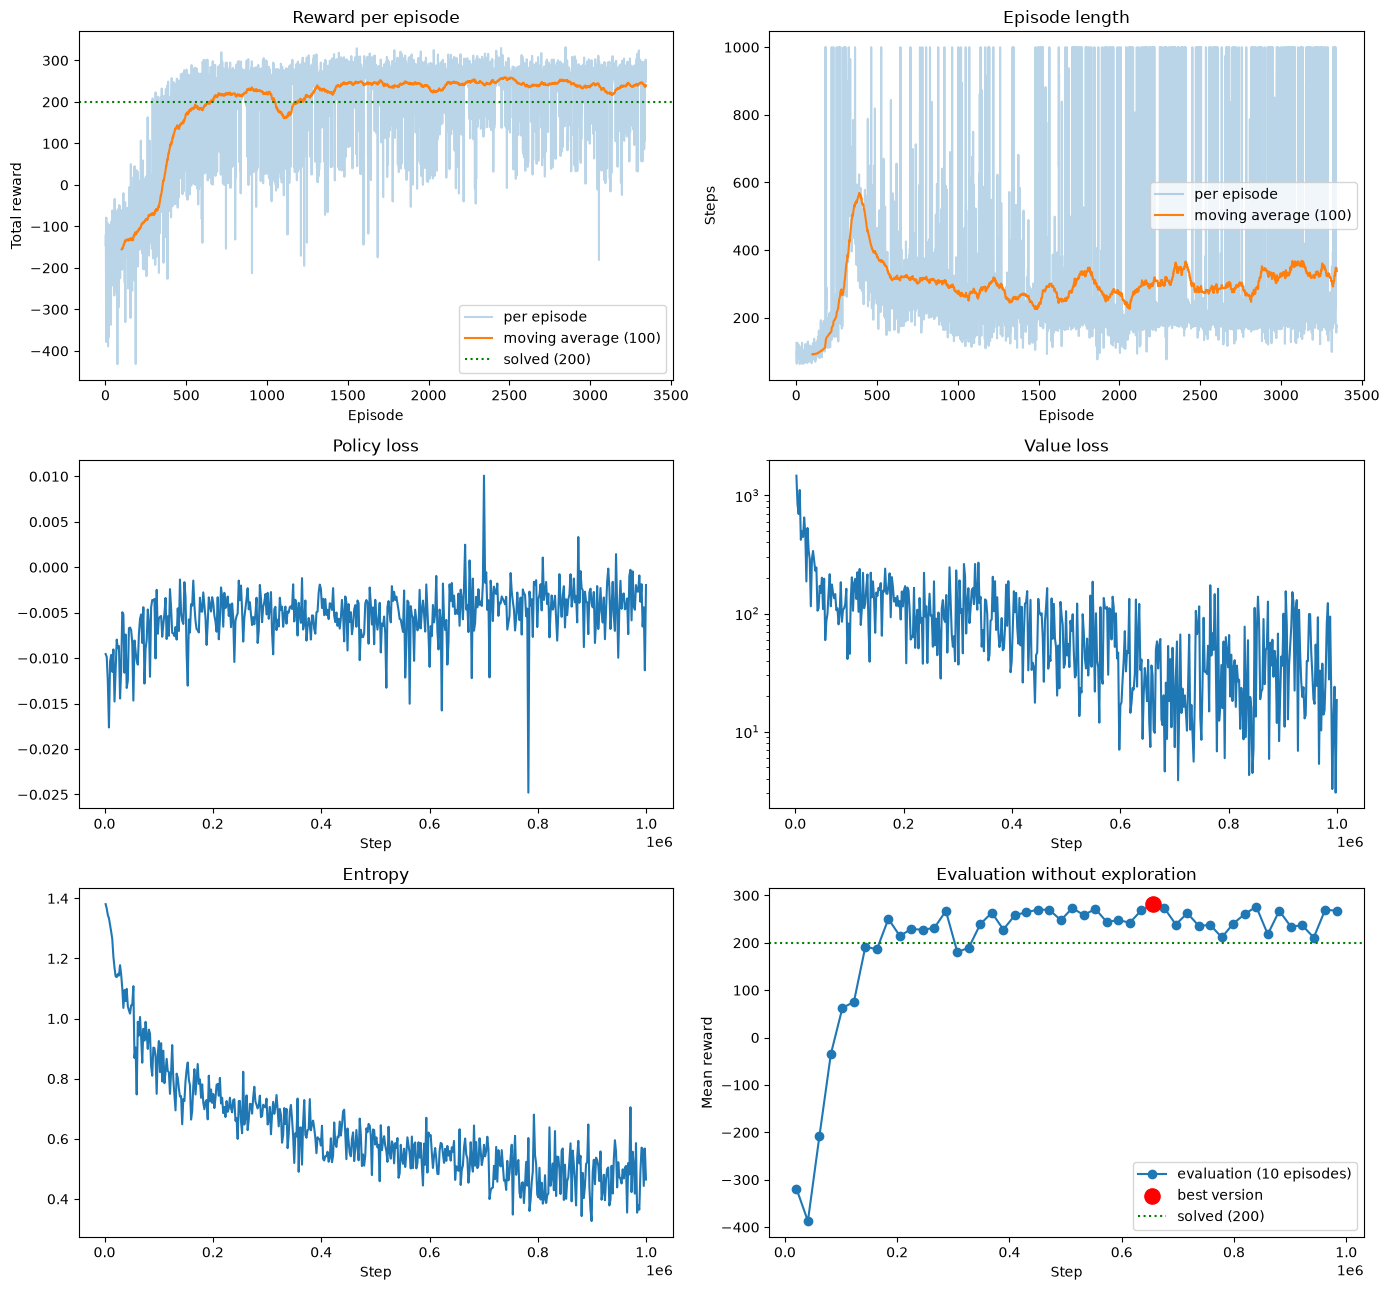

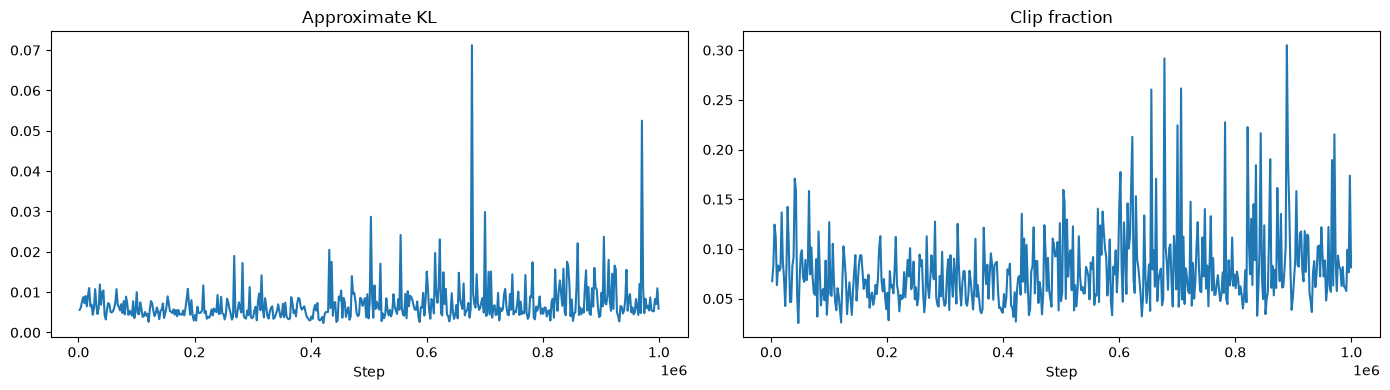

In [156]:
MOVING_AVERAGE_WINDOW = 100


def compute_moving_average(*, values: np.ndarray, window: int) -> np.ndarray:
    return np.convolve(values, np.ones(window) / window, mode="valid")


def plot_with_moving_average(*, axis: plt.Axes, values: np.ndarray, window: int, title: str, ylabel: str) -> None:
    episodes = np.arange(1, len(values) + 1)
    axis.plot(episodes, values, alpha=0.3, label="per episode")
    axis.plot(episodes[window - 1:], compute_moving_average(values=values, window=window), label=f"moving average ({window})")
    axis.set_title(title)
    axis.set_xlabel("Episode")
    axis.set_ylabel(ylabel)


def plot_training_curves(*, result: TrainingResult, config: PPOConfig) -> None:
    rewards = np.array([episode.total_reward for episode in result.episodes])
    lengths = np.array([episode.n_steps for episode in result.episodes])
    update_steps = np.arange(1, len(result.update_stats) + 1) * config.n_steps
    evaluation_steps = [evaluation.step for evaluation in result.evaluations]
    evaluation_rewards = [evaluation.mean_reward for evaluation in result.evaluations]

    figure, axes = plt.subplots(3, 2, figsize=(14, 13))

    plot_with_moving_average(axis=axes[0, 0], values=rewards, window=MOVING_AVERAGE_WINDOW, title="Reward per episode", ylabel="Total reward")
    axes[0, 0].axhline(SOLVED_THRESHOLD, color="green", linestyle=":", label=f"solved ({SOLVED_THRESHOLD:.0f})")
    axes[0, 0].legend()

    plot_with_moving_average(axis=axes[0, 1], values=lengths, window=MOVING_AVERAGE_WINDOW, title="Episode length", ylabel="Steps")
    axes[0, 1].legend()

    update_curves = (
        (axes[1, 0], [stats.policy_loss for stats in result.update_stats], "Policy loss"),
        (axes[1, 1], [stats.value_loss for stats in result.update_stats], "Value loss"),
        (axes[2, 0], [stats.entropy for stats in result.update_stats], "Entropy"),
    )
    for axis, values, title in update_curves:
        axis.plot(update_steps, values)
        axis.set_title(title)
        axis.set_xlabel("Step")
    axes[1, 1].set_yscale("log")

    axes[2, 1].plot(evaluation_steps, evaluation_rewards, marker="o", label="evaluation (10 episodes)")
    axes[2, 1].scatter([result.best_evaluation.step], [result.best_evaluation.mean_reward], color="red", s=120, zorder=3, label="best version")
    axes[2, 1].axhline(SOLVED_THRESHOLD, color="green", linestyle=":", label=f"solved ({SOLVED_THRESHOLD:.0f})")
    axes[2, 1].set_title("Evaluation without exploration")
    axes[2, 1].set_xlabel("Step")
    axes[2, 1].set_ylabel("Mean reward")
    axes[2, 1].legend()

    figure.tight_layout()
    plt.show()


def plot_update_health(*, result: TrainingResult, config: PPOConfig) -> None:
    update_steps = np.arange(1, len(result.update_stats) + 1) * config.n_steps
    figure, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(update_steps, [stats.approx_kl for stats in result.update_stats])
    axes[0].set_title("Approximate KL")
    axes[1].plot(update_steps, [stats.clip_fraction for stats in result.update_stats])
    axes[1].set_title("Clip fraction")
    for axis in axes:
        axis.set_xlabel("Step")
    figure.tight_layout()
    plt.show()


plot_training_curves(result=training_result, config=config)
plot_update_health(result=training_result, config=config)

### Termination statistics

The training episodes are split into 5 phases of equal size, each summarized with `summarize_results`. The number of steps needed to learn (first time the moving average reaches 200) and the duration are used for the comparison with DQN.

In [157]:
N_TRAINING_PHASES = 5

phase_indices = np.array_split(np.arange(len(training_result.episodes)), N_TRAINING_PHASES)
print(f"{'phase':<7}{'episodes':>10}{'reward':>9}{'steps':>8}" + "".join(f"{reason:>17}" for reason in END_REASONS))
for phase, indices in enumerate(phase_indices, start=1):
    phase_summary = summarize_results(results=training_result.episodes[indices[0]:indices[-1] + 1])
    print(
        f"{phase:<7}{len(indices):>10}{phase_summary.mean_reward:>9.1f}{phase_summary.mean_steps:>8.1f}"
        + "".join(f"{phase_summary.end_reasons[reason]:>17}" for reason in END_REASONS)
    )

training_rewards = np.array([episode.total_reward for episode in training_result.episodes])
episode_end_steps = np.cumsum([episode.n_steps for episode in training_result.episodes])
moving_average = compute_moving_average(values=training_rewards, window=MOVING_AVERAGE_WINDOW)
solved_positions = np.flatnonzero(moving_average >= SOLVED_THRESHOLD)

print(f"\nEpisodes played: {len(training_result.episodes)}")
print(f"Final moving average ({MOVING_AVERAGE_WINDOW} episodes): {moving_average[-1]:.1f}")
print(f"Best moving average: {moving_average.max():.1f}")
if solved_positions.size > 0:
    first_solved_episode = solved_positions[0] + MOVING_AVERAGE_WINDOW - 1
    print(f"Moving average first above {SOLVED_THRESHOLD:.0f} at episode {first_solved_episode + 1}, step {episode_end_steps[first_solved_episode]:,}")
else:
    print(f"The moving average never reached {SOLVED_THRESHOLD:.0f}")
print(f"Training duration: {training_result.duration / 60:.1f} min")

phase    episodes   reward   steps            crash  out_of_viewport          at_rest        truncated
1             670     38.7   304.0              341               36              276               17
2             669    211.4   288.1              107                2              541               19
3             669    241.0   277.5               51                0              578               40
4             669    245.7   299.4               27                0              564               78
5             669    238.9   324.3               28                0              553               88

Episodes played: 3346
Final moving average (100 episodes): 240.1
Best moving average: 259.1
Moving average first above 200 at episode 650, step 198,192
Training duration: 4.6 min


### Training results

| Measure | Value |
|---|---|
| training duration | about 5 min on a laptop CPU |
| moving average first above 200 | episode 650, step 198,192 |
| final and best moving average | 240.1 and 259.1 |
| best evaluation (10 episodes, no exploration) | 281.6 at step 655,360 |
| saved model | 43 KB, same score once reloaded |

| Phase | Mean reward | Mean steps | Crash | Out of viewport | At rest | Truncated |
|---|---|---|---|---|---|---|
| 1 | 38.7 | 304.0 | 341 | 36 | 276 | 17 |
| 2 | 211.4 | 288.1 | 107 | 2 | 541 | 19 |
| 3 | 241.0 | 277.5 | 51 | 0 | 578 | 40 |
| 4 | 245.7 | 299.4 | 27 | 0 | 564 | 78 |
| 5 | 238.9 | 324.3 | 28 | 0 | 553 | 88 |

**The agent learns to land within 20% of the budget.** The moving average reaches 200 after about one minute of training and stays between 220 and 260. Crashes fall from 51% to 4% of the episodes, and the lander comes to rest in more than 80% of them from phase 2 on (training episodes, with exploration). The episode length shows three stages: short episodes that end in a crash, then a peak near 570 steps around episode 400 when the agent hovers without landing, then about 300 steps once it lands.

**The updates stay healthy.** The value loss drops from about 1500 to between 3 and 100, the entropy decreases steadily from 1.39 to about 0.45, and the approximate KL stays mostly below 0.02.

**Weak points:**

* a dip of the moving average to about 170 around episode 1100, corrected by the next rollouts: PPO does not guarantee a monotonic progress;
* more truncated episodes at the end (88 in phase 5): the agent sometimes hovers until the time limit and loses the landing bonus;
* a plateau around 240 from step 400,000 on, with more irregular updates (KL spikes up to 0.07, clip fraction up to 0.3). A decreasing learning rate is a candidate experiment for section 9.

### Watching the agent

The saved model plays a few episodes without exploration, shown as an animation below the cell: the environment is created with `render_mode="rgb_array"` and each frame is drawn with matplotlib. A pygame window opened from a Jupyter kernel cannot be closed properly on macOS; `model.py` shows the agent in a real window.

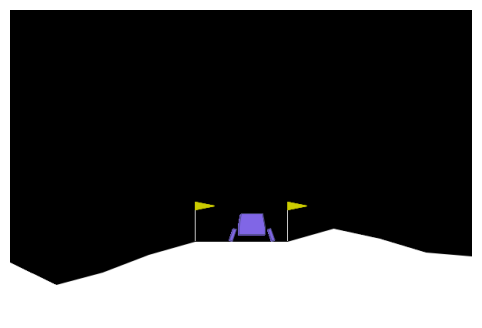

Episode 1: 270.2 in 269 steps (at_rest)
Episode 2: 279.6 in 199 steps (at_rest)
Episode 3: 286.8 in 180 steps (at_rest)
Episode 4: 260.1 in 203 steps (at_rest)
Episode 5: 299.5 in 204 steps (at_rest)


In [158]:
N_WATCHED_EPISODES = 5
WATCH_FIGURE_SIZE = (6, 4)


def make_rendering_agent(*, agent: Agent, env: gym.Env, show_frame: Callable[..., None]) -> Agent:
    def rendering_agent(*, state: np.ndarray) -> int:
        show_frame(frame=env.render())
        return agent(state=state)

    return rendering_agent


def watch_agent(*, agent: Agent, n_episodes: int, seed: int) -> list[EpisodeResult]:
    env = gym.make(ENV_ID, render_mode="rgb_array")
    env.reset(seed=seed)
    figure, axis = plt.subplots(figsize=WATCH_FIGURE_SIZE)
    axis.axis("off")
    image = axis.imshow(env.render())
    display_handle = display(figure, display_id=True)

    def show_frame(*, frame: np.ndarray) -> None:
        image.set_data(frame)
        display_handle.update(figure)

    rendering_agent = make_rendering_agent(agent=agent, env=env, show_frame=show_frame)
    results = [run_episode(env=env, agent=rendering_agent) for _ in range(n_episodes)]
    plt.close(figure)
    env.close()
    return results


watched_results = watch_agent(
    agent=make_greedy_agent(actor=load_ppo_actor(path=MODEL_PATH)),
    n_episodes=N_WATCHED_EPISODES,
    seed=SEED,
)
for episode, result in enumerate(watched_results, start=1):
    print(f"Episode {episode}: {result.total_reward:.1f} in {result.n_steps} steps ({result.end_reason})")